# Import Lib


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix


from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# 1.Data understanding
* Read Data
* Random Sample Data 
* Size of Data 
* Information of Data
* Check Names of Columns 
* Check Description 

In [19]:
df=pd.read_csv('C:\\Users\\Windows 10\\Desktop\\machine\\DATA SET\\AB_NYC_2019.csv')

* pd.read_csv() reads a CSV file and loads its data into a Pandas DataFrame.
* AB_NYC_2019.csv is a dataset containing Airbnb listings in New York City in 2019.

In [20]:
df.head(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


**Observation**: The first five rows provide an initial overview of the dataset, including the column names and sample values for each feature.

In [21]:
df.shape

(48895, 16)

**Observation:** The dataset contains 48,895 rows and 16 columns, providing information about Airbnb listings in New York City in 2019.

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

**Observation:**

The dataset contains 48,895 rows and 16 columns. Each row represents an Airbnb listing in New York City in 2019.

The dataset includes numerical and categorical features describing listing prices, locations, room types, host information, minimum nights, reviews, and availability.

The `price` column is the target variable for the regression task.

The dataset contains three main data types:
- **Integer (`int64`):** 7 columns, representing whole-number values such as `price`, `minimum_nights`, and `number_of_reviews`.
- **Float (`float64`):** 3 columns, representing decimal values such as `latitude`, `longitude`, and `reviews_per_month`.
- **String (`str`):** 6 columns, representing text data such as `name`, `host_name`, and `room_type`.

The `info()` output reveals missing values in four columns:
- **`name`:** 16 missing values.
- **`host_name`:** 21 missing values.
- **`last_review`:** 10,052 missing values.
- **`reviews_per_month`:** 10,052 missing values.

The remaining 12 columns contain no missing values.

These missing values will be investigated during the data-cleaning stage to determine the most appropriate treatment for each column.

In [23]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365']

In [24]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


**Observation:**

The descriptive statistics show considerable variation in Airbnb listing prices. The average price is approximately $152.72, while the median price is $106. This difference suggests a right-skewed price distribution, potentially influenced by high-priced listings.

The minimum price is $0, and the maximum price is $10,000. These values require further investigation to identify potential invalid values and outliers before making any treatment decisions.

The `minimum_nights` column has a maximum value of 1,250 nights, which may represent an unusual listing and should be investigated. The `number_of_reviews` column also shows substantial variation, with a maximum of 629 reviews.

The `reviews_per_month` column contains 38,843 non-missing values, indicating that 10,052 values are missing. Finally, the `availability_365` column ranges from 0 to 365 days, showing differences in listing availability.

These findings will guide further data exploration, visualization, and outlier analysis.

# 2.Data Cleaning
* Missing Values 
* Duplicate Rows 
* Outlier Detection
* Outlier Treatment Techniques 

In [25]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

**Observation**
The missing values analysis reveals that the dataset contains missing values in four columns.

- `name`: 16 missing values .
- `host_name`: 21 missing values .
- `last_review`: 10,052 missing values .
- `reviews_per_month`: 10,052 missing values .

The remaining 12 columns contain no missing values.

In [26]:
df.duplicated().sum()

np.int64(0)

**Observation**

The `df.duplicated().sum()` command returned 0, indicating that the dataset contains no fully duplicated rows. Therefore, no rows need to be removed due to complete duplication at this stage.

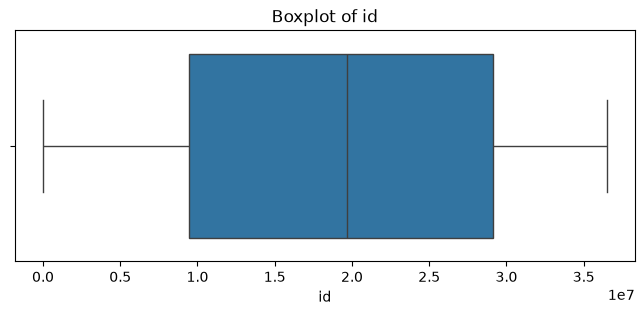

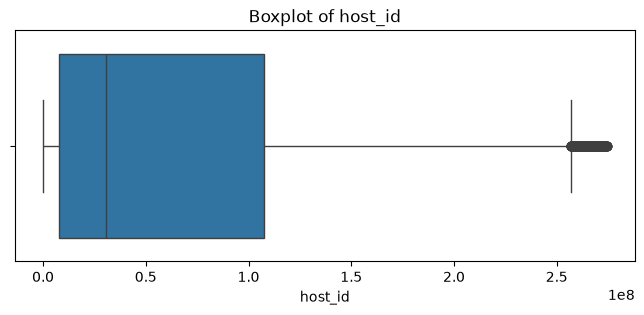

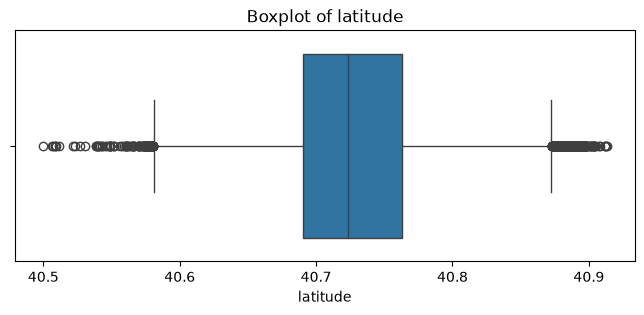

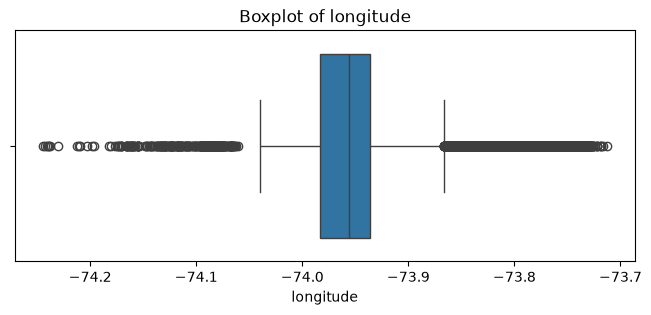

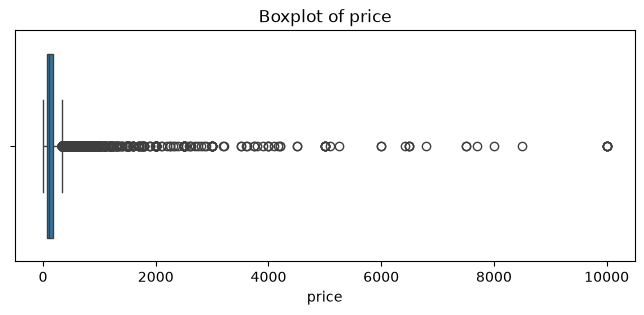

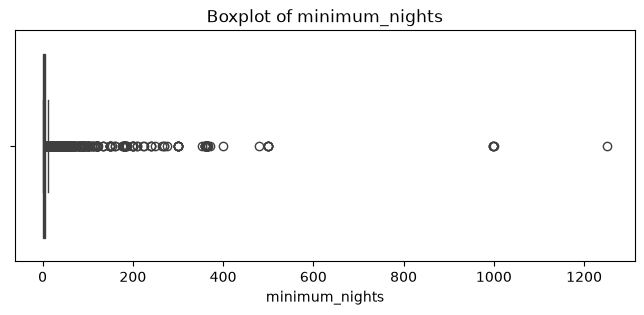

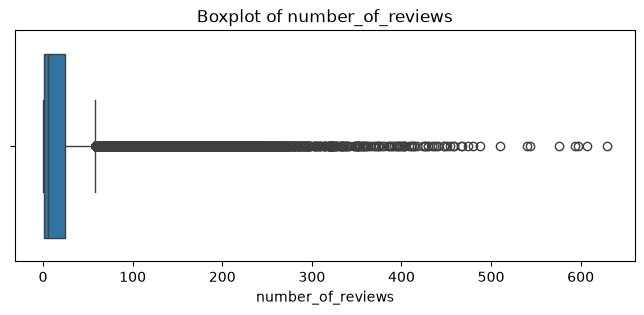

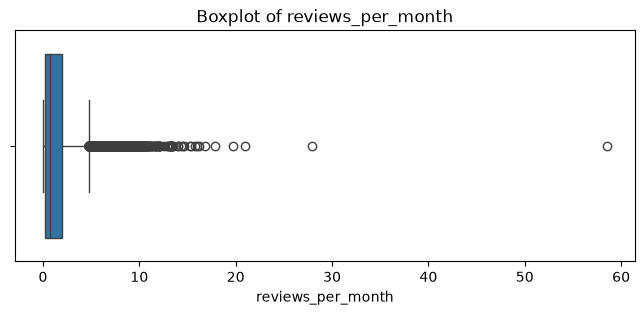

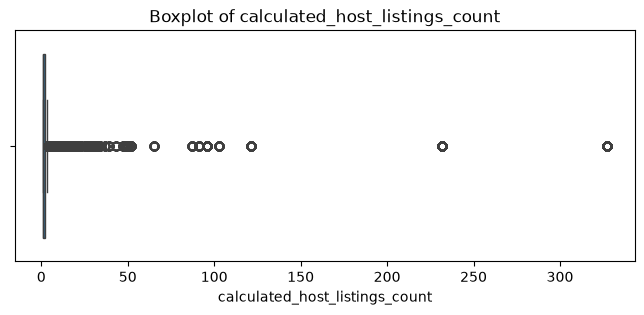

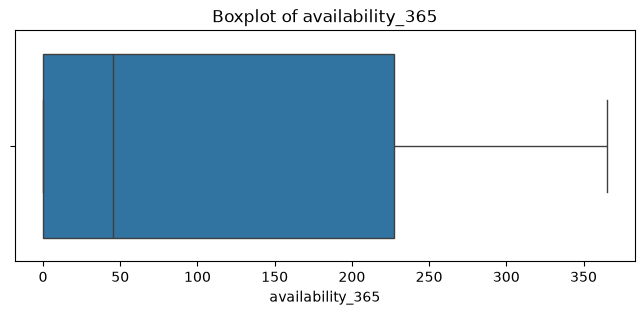

In [28]:
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


In [1]:
import sys
print(sys.executable)
import numpy, pandas, sklearn
print("OK")

c:\Users\HP\anaconda3\python.exe
OK
